# **Baseline XGBoost Model for (Static) Clinical Data**
This notebook trains an XGBoost model using publicly available neonatal clinical data with its default parameters (no fine-tuning)

In [1]:
import pandas as pd
import sklearn as sk
import xgboost as xgb
import matplotlib.pyplot as plt

In [2]:
RANDOM_SEED = 42
DATASET_PATH = '../datasets/static_clinical_data.csv'
MODEL_PATH = '../models/baseline_xgb_model.json'
TARGET_COLUMN = 'has_sepsis'

## **Data Preparation and Preprocessing**

In [3]:
dataset = pd.read_csv(DATASET_PATH)
dataset = dataset.drop('patient_id', axis=1)
dataset.shape

(1706, 16)

In [4]:
dataset.head()

,sex,gestational_age_at_birth_weeks,birth_weight_kg,has_sepsis,onset_age_in_days,intubated_at_time_of_sepsis_evaluation,inotrope_at_time_of_sepsis_eval,central_venous_line,umbilical_arterial_line,ecmo,temp_celsius,comorbidity_necrotizing_enterocolitis,comorbidity_chronic_lung_disease,comorbidity_cardiac,comorbidity_surgical,comorbidity_ivh_or_shunt
0,0.0,23.0,0.40,1,7.0,1.0,0.0,1.0,1.0,0.0,37.6,0.0,0.0,0.0,0.0,1.0
1,0.0,27.0,0.79,1,0.0,1.0,0.0,1.0,1.0,0.0,36.8,0.0,0.0,0.0,0.0,0.0
2,0.0,27.0,0.79,1,23.0,1.0,1.0,1.0,0.0,0.0,36.9,0.0,0.0,0.0,0.0,0.0
3,0.0,37.0,4.31,1,11.0,1.0,0.0,1.0,1.0,0.0,37.2,0.0,0.0,0.0,0.0,0.0
4,1.0,39.0,4.17,0,3.0,1.0,0.0,0.0,1.0,0.0,36.2,0.0,0.0,0.0,0.0,0.0


In [5]:
dataset.describe()

,sex,gestational_age_at_birth_weeks,birth_weight_kg,has_sepsis,onset_age_in_days,intubated_at_time_of_sepsis_evaluation,inotrope_at_time_of_sepsis_eval,central_venous_line,umbilical_arterial_line,ecmo,temp_celsius,comorbidity_necrotizing_enterocolitis,comorbidity_chronic_lung_disease,comorbidity_cardiac,comorbidity_surgical,comorbidity_ivh_or_shunt
count,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000
mean,0.575029,32.418629,2.039844,0.331184,63.032825,0.650645,0.084408,0.686401,0.115475,0.043376,37.503423,0.169402,0.287808,0.185815,0.351700,0.136577
std,0.494483,5.272560,1.110173,0.470777,69.639845,0.476906,0.278080,0.464092,0.319688,0.203762,0.746329,0.375217,0.452874,0.389071,0.477641,0.343501
min,0.000000,22.000000,0.370000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,33.700000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,27.000000,0.920000,0.000000,9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,34.000000,2.130000,0.000000,37.500000,1.000000,0.000000,1.000000,0.000000,0.000000,37.300000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,37.000000,2.950000,1.000000,98.000000,1.000000,0.000000,1.000000,0.000000,0.000000,38.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,1.000000,41.000000,5.950000,1.000000,335.000000,1.000000,1.000000,1.000000,1.000000,1.000000,41.300000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
dataset.isnull().sum()

sex                                       0
gestational_age_at_birth_weeks            0
birth_weight_kg                           0
has_sepsis                                0
onset_age_in_days                         0
intubated_at_time_of_sepsis_evaluation    0
inotrope_at_time_of_sepsis_eval           0
central_venous_line                       0
umbilical_arterial_line                   0
ecmo                                      0
temp_celsius                              0
comorbidity_necrotizing_enterocolitis     0
comorbidity_chronic_lung_disease          0
comorbidity_cardiac                       0
comorbidity_surgical                      0
comorbidity_ivh_or_shunt                  0
dtype: int64

In [7]:
train_data, test_data = sk.model_selection.train_test_split(dataset, test_size=0.2, random_state=RANDOM_SEED, stratify=dataset[TARGET_COLUMN])

## **Model Setup and Training**

In [8]:
xgb_model = xgb.XGBClassifier(random_state=RANDOM_SEED)

In [9]:
xgb_model.fit(train_data.drop(TARGET_COLUMN, axis=1), train_data[TARGET_COLUMN])

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## **Baseline Model Evaluation**

In [10]:
test_predictions = xgb_model.predict(test_data.drop(TARGET_COLUMN, axis=1))

In [11]:
accuracy = xgb_model.score(test_data.drop(TARGET_COLUMN, axis=1), test_data[TARGET_COLUMN])
precision = sk.metrics.precision_score(test_data[TARGET_COLUMN], test_predictions)
recall = sk.metrics.recall_score(test_data[TARGET_COLUMN], test_predictions)
f1 = sk.metrics.f1_score(test_data[TARGET_COLUMN], test_predictions)

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

Accuracy: 0.5994
Precision: 0.3696
Recall: 0.3009
F1 Score: 0.3317


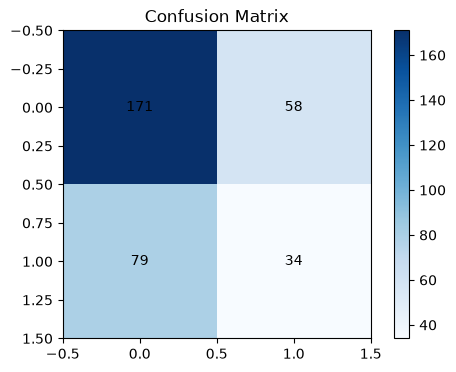

In [12]:
confusion_matrix = sk.metrics.confusion_matrix(test_data[TARGET_COLUMN], test_predictions)

plt.figure(figsize=(6, 4))
plt.imshow(confusion_matrix, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()

for i in range(confusion_matrix.shape[0]):
    for j in range(confusion_matrix.shape[1]):
        plt.text(j, i, str(confusion_matrix[i, j]), ha='center', va='center')

plt.show()

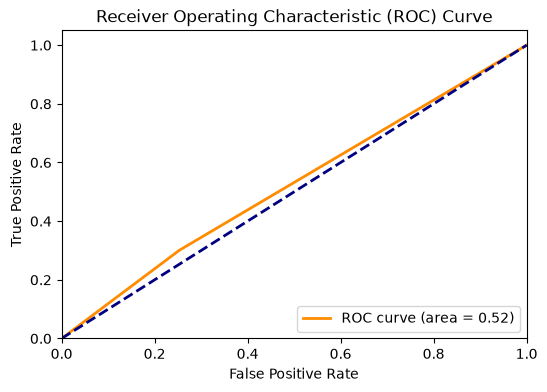

In [13]:
fpr, tpr, _ = sk.metrics.roc_curve(test_data[TARGET_COLUMN], test_predictions)
roc_auc = sk.metrics.auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

## **Exporting the Model**

In [14]:
xgb_model.save_model(MODEL_PATH)